# EllSeg pupil-centre validation against hand labels

Runs **the same EllSeg pipeline as your main notebook** (same weights, preprocessing, ellipse mode, blink/occlusion rule, px→deg approximation) on the frames you exported in step 1, then compares the pupil centres with the points you clicked in step 2.

**Before running** - make a Kaggle Dataset (Add Data → Upload) containing:

| file | from | required |
|---|---|---|
| `label_frames/` (the 50 PNGs) | step 1 | yes |
| `label_index.csv` | step 1 | yes |
| `labels.csv` | step 2 | yes |
| `cropped_eye.mp4` | step 1 | optional (better blink reference + iris scale, as in the full-video run) |
| `labels_pass2.csv` | step 2, second labelling pass | optional (measures your own labelling noise) |

Then attach the dataset to this notebook, turn **Internet on** (EllSeg is cloned from GitHub) and pick a **GPU** (CPU also works for 50 frames).

In [5]:
# ===================== CELL 1: config + find your uploaded files =====================
import os, sys, subprocess, shutil, warnings, argparse, json
from pathlib import Path
import numpy as np, pandas as pd, cv2

# ---- paths: leave as None to auto-find them inside /kaggle/input ----
LABELS_CSV   = None    # labels.csv          (step 2)
INDEX_CSV    = None    # label_index.csv     (step 1)
FRAMES_DIR   = "/kaggle/input/datasets/rzridazahra/validate/label_frames/label_frames"    # label_frames/       (step 1)
REF_VIDEO    = None    # optional: cropped_eye.mp4 (step 1)
LABELS_CSV_2 = None    # optional: second labelling pass, e.g. labels_pass2.csv

# ---- EllSeg settings: IDENTICAL to the main notebook ----
WEIGHTS = "all.git_ok"
ELLIPSES = 1                       # 1 = EllSeg's own (inferred) ellipses
NET_H, NET_W = 240, 320
BLINK_MIN_CONTRAST_FRAC = 0.25     # blink if contrast < this x typical open-eye contrast
BLINK_MAX_AXIS_RATIO = 3.0         # ... or the ellipse is a sliver
PARTIAL_OCC = 0.25                 # occlusion score above this (not a blink) = partially covered
IRIS_DIAM_MM = 11.7; EYE_R_MM = 12.0   # px -> deg approximation, same constants as Cell 3 of the main notebook
REF_MAX_FRAMES = 300               # frames used from REF_VIDEO for the blink reference / iris scale

WORK = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd()
OUT_DIR = WORK / "gt_eval"; OUT_DIR.mkdir(parents=True, exist_ok=True)

def find(name, is_dir=False, given=None):
    if given: return Path(given)
    root = Path("/kaggle/input") if Path("/kaggle/input").exists() else Path.cwd()
    hits = sorted(p for p in root.rglob(name) if p.is_dir() == is_dir)
    if len(hits) > 1: print(f"  note: several '{name}' found, using {hits[0]}")
    return hits[0] if hits else None

LABELS_CSV   = find("labels.csv", given=LABELS_CSV)
INDEX_CSV    = find("label_index.csv", given=INDEX_CSV)
FRAMES_DIR   = find("label_frames", is_dir=True, given=FRAMES_DIR)
REF_VIDEO    = find("cropped_eye.mp4", given=REF_VIDEO)
LABELS_CSV_2 = find("labels_pass2.csv", given=LABELS_CSV_2)

for k, p in [("labels", LABELS_CSV), ("index", INDEX_CSV), ("frames", FRAMES_DIR),
             ("ref video (optional)", REF_VIDEO), ("labels pass 2 (optional)", LABELS_CSV_2)]:
    print(f"{k:26s}: {p}")
missing = [k for k, p in [("labels.csv", LABELS_CSV), ("label_index.csv", INDEX_CSV), ("label_frames/", FRAMES_DIR)] if p is None]
if missing: raise FileNotFoundError(f"Not found in /kaggle/input: {missing}. Attach your dataset or set the paths above.")

labels                    : /kaggle/input/datasets/rzridazahra/validate/labels.csv
index                     : /kaggle/input/datasets/rzridazahra/validate/label_index.csv
frames                    : /kaggle/input/datasets/rzridazahra/validate/label_frames/label_frames
ref video (optional)      : None
labels pass 2 (optional)  : None


In [6]:
# ===================== CELL 2: load EllSeg (same as Cell 2 of the main notebook) =====================
# NumPy compatibility patch: MUST run before importing EllSeg (it uses np.int, np.float, ...)
for _n, _v in [("float", float), ("int", int), ("int0", np.intp), ("mat", np.asmatrix), ("bool", bool), ("object", object)]:
    if not hasattr(np, _n): setattr(np, _n, _v)

REPO = WORK / "EllSeg"
if not REPO.exists():
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/RSKothari/EllSeg.git", str(REPO)], check=True)
W_PATH = REPO / "weights" / WEIGHTS
if not W_PATH.exists() or W_PATH.stat().st_size < 1_000_000:
    print("Files in", REPO / "weights", ":", sorted(p.name for p in (REPO / "weights").glob("*")) if (REPO / "weights").exists() else "folder missing")
    raise FileNotFoundError(f"Pretrained weights not found / too small: {W_PATH}. Pick one of the files listed above via WEIGHTS = '...'")

import torch
warnings.filterwarnings("ignore")
sys.path.insert(0, str(REPO))
import evaluate_ellseg as ES                     # the repo's own inference code
from modelSummary import model_dict
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
try:
    netDict = torch.load(str(W_PATH), map_location=device, weights_only=False)
except TypeError:
    netDict = torch.load(str(W_PATH), map_location=device)
model = model_dict["ritnet_v3"]
model.load_state_dict(netDict["state_dict"], strict=True)
model.to(device).eval()
ES.args = argparse.Namespace(ellseg_ellipses=ELLIPSES, skip_ransac=0)   # evaluate_ellseg_on_image reads this global
print("EllSeg loaded on", device)

EllSeg loaded on cpu


In [7]:
# ===================== CELL 3: run EllSeg on the labelled frames =====================
def prep(rgb):
    """EllSeg input: grayscale 240x320, zero-mean / unit-std, shape [1,1,H,W]. (The crop is already 4:3: no padding needed.)"""
    g = cv2.resize(cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY), (NET_W, NET_H), interpolation=cv2.INTER_LANCZOS4)
    gf = g.astype(np.float32)
    return g, torch.from_numpy((gf - gf.mean()) / (gf.std() + 1e-6)).unsqueeze(0).unsqueeze(0)

def pupil_contrast(g, pm):
    """(surround - pupil) / surround on the REAL pixels under EllSeg's pupil mask. Open eye -> high; covered by lid -> ~0."""
    n = int(pm.sum())
    if n < 20: return np.nan
    r = max(3, int(0.6 * np.sqrt(n / np.pi)))
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * r + 1, 2 * r + 1))
    ring = (cv2.dilate(pm.astype(np.uint8), k) > 0) & ~pm
    if ring.sum() < 10: return np.nan
    inside, outside = float(g[pm].mean()), float(g[ring].mean())
    return (outside - inside) / max(outside, 1.0)

def valid_ellipse(e):
    e = np.asarray(e, float)
    return bool(e.shape[0] >= 5 and np.all(np.isfinite(e[:5])) and e[2] > 1 and e[3] > 1 and 0 <= e[0] < NET_W and 0 <= e[1] < NET_H)

nan5 = np.full(5, np.nan)

def run_ellseg(rgb_list):
    """Same per-frame logic as the main notebook. Returns pupil ellipses, iris ellipses, pupil contrast."""
    pe_l, ie_l, con_l = [], [], []
    with torch.no_grad():
        for i, f in enumerate(rgb_list):
            g, t_in = prep(f)
            pe, ie, con = nan5, nan5, np.nan
            if g.max() >= 20:                                     # (the repo also skips almost-black frames)
                try:
                    seg, _, pe_, ie_ = ES.evaluate_ellseg_on_image(t_in.to(device), model)
                    pe_ = np.asarray(pe_, float).reshape(-1)[:5]; ie_ = np.asarray(ie_, float).reshape(-1)[:5]
                    seg = np.asarray(seg)
                    con = pupil_contrast(g, seg == 2)
                    if valid_ellipse(pe_): pe = pe_
                    if valid_ellipse(ie_): ie = ie_
                except Exception as exc:
                    if i == 0: print("First-frame error:", repr(exc)[:300])
            pe_l.append(pe); ie_l.append(ie); con_l.append(con)
    return np.array(pe_l), np.array(ie_l), np.array(con_l, float)

def read_rgb(p):
    bgr = cv2.imread(str(p))
    if bgr is None: raise FileNotFoundError(p)
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

# ---- labelled frames ----
lab = pd.read_csv(LABELS_CSV).merge(pd.read_csv(INDEX_CSV), on="file", how="left")
imgs = [read_rgb(FRAMES_DIR / f) for f in lab.file]
CH, CW = imgs[0].shape[:2]                       # cropped-video pixel space (same space as the clicks)
assert all(im.shape[:2] == (CH, CW) for im in imgs), "frames have different sizes"
print(f"{len(imgs)} labelled frames, {CW}x{CH}")

pe, ie, con = run_ellseg(imgs)
found = np.isfinite(pe[:, 0])
print(f"Pupil ellipse returned in {int(found.sum())}/{len(found)} frames")

# ---- reference statistics (blink reference contrast + iris size for the px->deg scale) ----
if REF_VIDEO is not None:
    cap = cv2.VideoCapture(str(REF_VIDEO)); n_v = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)); step = max(1, n_v // REF_MAX_FRAMES)
    ref_imgs, i = [], 0
    while True:
        ok_, f = cap.read()
        if not ok_: break
        if i % step == 0: ref_imgs.append(cv2.cvtColor(f, cv2.COLOR_BGR2RGB))
        i += 1
    cap.release()
    print(f"Reference: {len(ref_imgs)} frames sampled from {REF_VIDEO.name} ({n_v} frames)")
    _, ref_ie, ref_con_arr = run_ellseg(ref_imgs)
else:
    ref_ie, ref_con_arr = ie, con
    print("Reference: the labelled frames themselves (add cropped_eye.mp4 to the dataset for the full-video reference)")

ref_con = np.nanpercentile(ref_con_arr[np.isfinite(ref_con_arr)], 75) if np.isfinite(ref_con_arr).any() else 1.0
_ir = np.maximum(ref_ie[:, 2], ref_ie[:, 3]); _ir = _ir[np.isfinite(_ir)]
mm_per_px = IRIS_DIAM_MM / (2 * np.median(_ir) * (CW / NET_W))          # cropped-video px -> mm (same formula as Cell 3)
print(f"reference open-eye contrast {ref_con:.2f} | 1 px = {mm_per_px:.4f} mm = {np.degrees(np.arcsin(mm_per_px / EYE_R_MM)):.3f} deg")

# ---- blink / occlusion flags: same rule as the main notebook (no temporal padding: frames are isolated) ----
ratio = np.maximum(pe[:, 2], pe[:, 3]) / np.maximum(np.minimum(pe[:, 2], pe[:, 3]), 1e-6)
blink = (~found) | (~np.isfinite(con)) | (con < BLINK_MIN_CONTRAST_FRAC * ref_con) | (np.nan_to_num(ratio, nan=1.0) > BLINK_MAX_AXIS_RATIO)
occl = np.clip(1.0 - np.nan_to_num(con, nan=0.0) / max(ref_con, 1e-6), 0, 1)
partial = (occl > PARTIAL_OCC) & ~blink & found

# ---- model pupil centre in cropped-video pixels (same conversion as the main notebook) ----
pred_x = pe[:, 0] * (CW / NET_W)
pred_y = pe[:, 1] * (CH / NET_H)
print(f"Flagged blink/no-pupil: {int(blink.sum())} | partially occluded: {int(partial.sum())}")

50 labelled frames, 616x462
Pupil ellipse returned in 50/50 frames
Reference: the labelled frames themselves (add cropped_eye.mp4 to the dataset for the full-video reference)
reference open-eye contrast 0.61 | 1 px = 0.0790 mm = 0.377 deg
Flagged blink/no-pupil: 6 | partially occluded: 7


=== Detection / blink agreement ===
You skipped (pupil not visible): 0  | model also flagged blink/no-pupil on 0 of them
You labelled a pupil:            50  | model wrongly flagged blink/no-pupil on 6 of them

=== Overall ===
n              50.000
mean_px        26.445
median_px       3.735
rmse_px        72.678
p95_px        216.647
max_px        264.204
bias_x        -20.270
bias_y         -3.498
median_deg      1.409
p95_deg        90.000

=== By category (step-1 proxy categories) ===
                   n  mean_px  median_px  rmse_px  p95_px  max_px  bias_x  bias_y  median_deg  p95_deg
extreme_left     8.0     3.01       3.33     3.31    4.76    5.16    1.55   -1.09        1.26     1.80
extreme_right    8.0   115.65      98.94   161.68  259.89  264.20 -109.33  -14.20       46.17    90.00
fast_motion      8.0    35.96       6.23    82.57  156.49  232.29  -26.25   -9.48        2.35    60.58
possible_blink   8.0     4.50       3.83     4.77    7.07    7.54    3.55    2.16        1.44 

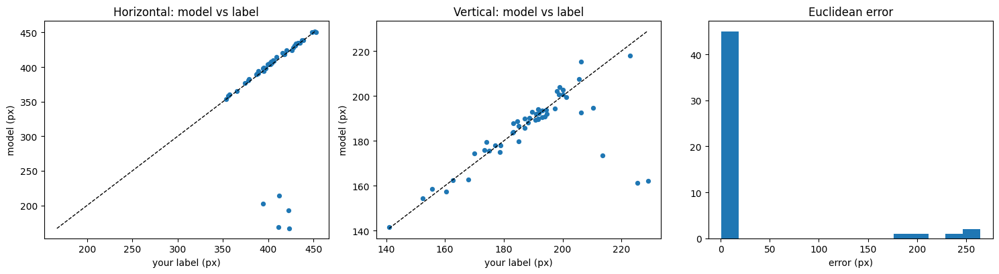

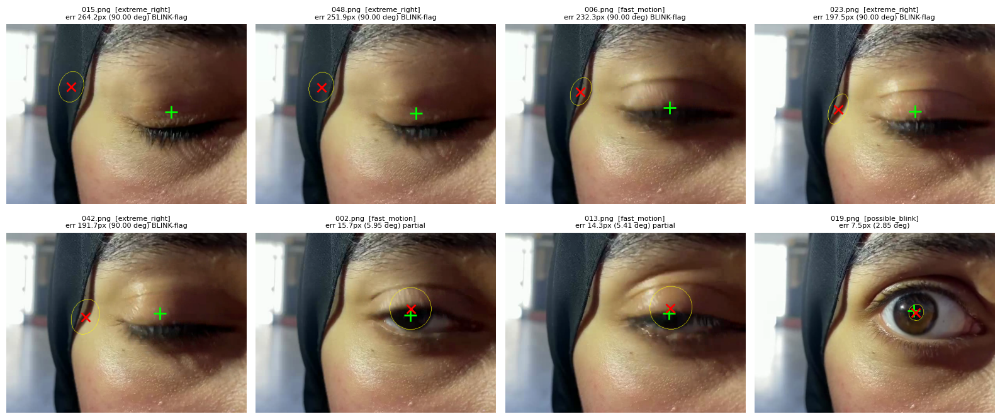

Saved to /kaggle/working/gt_eval : ['gt_all_frames.csv', 'gt_comparison.csv', 'gt_scatter.png', 'gt_worst_frames.png']


In [8]:
# ===================== CELL 4: compare with your hand labels =====================
import matplotlib.pyplot as plt

lab["pred_x"], lab["pred_y"] = pred_x, pred_y
lab["found"], lab["model_blink"], lab["partial"] = found, blink, partial
lab["contrast"], lab["ellipse_ratio"] = con, ratio

vis = lab[["x", "y"]].notna().all(axis=1)                 # you could see the pupil
mod_none = lab.model_blink | ~np.isfinite(lab.pred_x)     # model said blink / no pupil

# ---- 1) detection / blink agreement ----
print("=== Detection / blink agreement ===")
print(f"You skipped (pupil not visible): {int((~vis).sum())}  | model also flagged blink/no-pupil on {int((mod_none & ~vis).sum())} of them")
print(f"You labelled a pupil:            {int(vis.sum())}  | model wrongly flagged blink/no-pupil on {int((mod_none & vis).sum())} of them")

# ---- 2) localisation error (only frames where you labelled a pupil AND the model returned one) ----
d = lab[vis & np.isfinite(lab.pred_x)].copy()
if len(d) == 0: raise RuntimeError("No frame has both a label and a model prediction.")
d["dx"] = d.pred_x - d.x            # + = model is to the right of your label
d["dy"] = d.pred_y - d.y            # + = model is below your label
d["err_px"] = np.hypot(d.dx, d.dy)
d["err_mm"] = d.err_px * mm_per_px
d["err_deg"] = np.degrees(np.arcsin(np.clip(d.err_mm / EYE_R_MM, -1, 1)))
d["err_iris_pct"] = 100 * d.err_px / (np.median(_ir) * (CW / NET_W))   # error as % of the iris radius

def summ(g):
    return pd.Series(dict(
        n=len(g), mean_px=g.err_px.mean(), median_px=g.err_px.median(),
        rmse_px=np.sqrt((g.err_px ** 2).mean()), p95_px=g.err_px.quantile(.95), max_px=g.err_px.max(),
        bias_x=g.dx.mean(), bias_y=g.dy.mean(),
        median_deg=g.err_deg.median(), p95_deg=g.err_deg.quantile(.95)))

print("\n=== Overall ===")
print(summ(d).round(3).to_string())
print("\n=== By category (step-1 proxy categories) ===")
print(pd.DataFrame({c: summ(g) for c, g in d.groupby("category")}).T.round(2).to_string())

# ---- 3) gain check: does the model reproduce amplitude? ----
if len(d) >= 3:
    sx, ox = np.polyfit(d.x, d.pred_x, 1)
    sy, oy = np.polyfit(d.y, d.pred_y, 1)
    print(f"\nGain (model vs label): horizontal slope = {sx:.3f}, vertical slope = {sy:.3f}   (1.000 = perfect; <1 = amplitude underestimated)")
    print(f"Label range: x {d.x.min():.1f}..{d.x.max():.1f} px ({d.x.max() - d.x.min():.1f} px span)  <- a small span makes the slope noisy")

# ---- 4) optional: your own labelling noise (second pass) ----
if LABELS_CSV_2 is not None:
    l2 = pd.read_csv(LABELS_CSV_2).rename(columns={"x": "x2", "y": "y2"})
    m = d.merge(l2, on="file")
    m = m[m[["x2", "y2"]].notna().all(axis=1)]
    if len(m):
        hum = np.hypot(m.x - m.x2, m.y - m.y2)
        print(f"\nHuman repeatability (pass 1 vs pass 2, n={len(m)}): median {hum.median():.2f} px, p95 {hum.quantile(.95):.2f} px")
        print(f"Model vs pass 1 on the same frames:            median {m.err_px.median():.2f} px, p95 {m.err_px.quantile(.95):.2f} px")
        print("-> a model error close to the human repeatability cannot be told apart from your labelling noise.")

# ---- plots ----
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for a, (lx, ly, t) in zip(ax[:2], [(d.x, d.pred_x, "Horizontal"), (d.y, d.pred_y, "Vertical")]):
    a.scatter(lx, ly, s=18); lo, hi = min(lx.min(), ly.min()), max(lx.max(), ly.max())
    a.plot([lo, hi], [lo, hi], "k--", lw=1); a.set_xlabel("your label (px)"); a.set_ylabel("model (px)"); a.set_title(f"{t}: model vs label")
ax[2].hist(d.err_px, bins=15); ax[2].set_xlabel("error (px)"); ax[2].set_title("Euclidean error")
plt.tight_layout(); fig.savefig(OUT_DIR / "gt_scatter.png", dpi=110); plt.show()

# ---- 5) look at the worst frames: green + = your label, red x = model centre, yellow = model pupil ellipse ----
worst = d.sort_values("err_px", ascending=False).head(8)
fig, axes = plt.subplots(2, 4, figsize=(16, 7)); axes = axes.ravel()
for a in axes: a.axis("off")
for a, (i, r) in zip(axes, worst.iterrows()):
    im = imgs[i].copy()
    sx_, sy_ = CW / NET_W, CH / NET_H
    pe_i = pe[i]
    cv2.ellipse(im, (int(pe_i[0] * sx_), int(pe_i[1] * sy_)), (max(1, int(pe_i[2] * sx_)), max(1, int(pe_i[3] * sy_))),
                float(np.degrees(pe_i[4])), 0, 360, (255, 255, 0), 1)
    a.imshow(im)
    a.plot(r.x, r.y, "+", color="lime", ms=14, mew=2)
    a.plot(r.pred_x, r.pred_y, "x", color="red", ms=10, mew=2)
    flag = " BLINK-flag" if r.model_blink else (" partial" if r.partial else "")
    a.set_title(f"{r.file}  [{r.category}]\nerr {r.err_px:.1f}px ({r.err_deg:.2f} deg){flag}", fontsize=8)
plt.tight_layout(); fig.savefig(OUT_DIR / "gt_worst_frames.png", dpi=110); plt.show()

d.drop(columns=["found"]).to_csv(OUT_DIR / "gt_comparison.csv", index=False)
lab.to_csv(OUT_DIR / "gt_all_frames.csv", index=False)
print("Saved to", OUT_DIR, ":", sorted(p.name for p in OUT_DIR.glob("*")))

Image size (cropped-video px): 616x462   (the Kaggle run used 416x312)
6 failing frames (> 15 px), 44 fine frames

   file      category     x     y  pred_x  pred_y  err_px  dist_to_right_edge  contrast  ellipse_ratio  model_blink  partial
042.png extreme_right 394.3 206.3   202.9   215.4   191.7               221.7       NaN            1.3         True    False
002.png   fast_motion 397.3 210.3   397.8   194.6    15.7               218.7       0.3            1.0        False     True
048.png extreme_right 411.0 229.0   168.1   162.3   251.9               205.0       0.0            1.2         True    False
023.png extreme_right 412.0 223.0   214.5   218.0   197.5               204.0      -0.2            1.9         True    False
006.png   fast_motion 422.0 213.7   193.2   173.6   232.3               194.0       0.1            1.5         True    False
015.png extreme_right 423.0 225.3   166.7   161.3   264.2               193.0       0.0            1.3         True    False

=== Stats

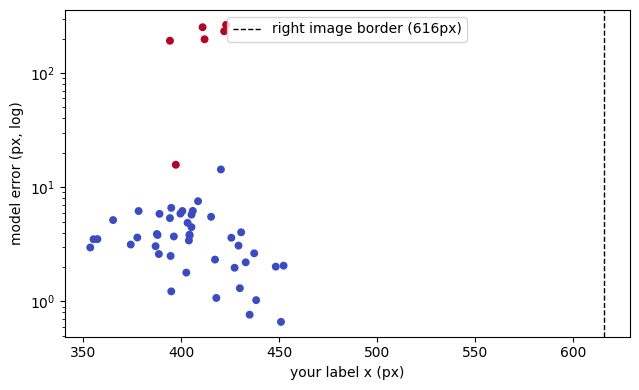

In [9]:
# ===== DIAGNOSE: why do some frames fail? (paste as a new cell AFTER Cell 4 of ellseg_gt_evaluation.ipynb) =====
import numpy as np, matplotlib.pyplot as plt

THR = 15   # px error above which a frame counts as a failure

print(f"Image size (cropped-video px): {CW}x{CH}   (the Kaggle run used 416x312)")
fail = d[d.err_px > THR].copy()
good = d[d.err_px <= THR].copy()
print(f"{len(fail)} failing frames (> {THR} px), {len(good)} fine frames\n")

fail["dist_to_right_edge"] = CW - fail.x      # small / negative -> pupil at or beyond the crop border
fail["dist_to_left_edge"] = fail.x
cols = ["file", "category", "x", "y", "pred_x", "pred_y", "err_px",
        "dist_to_right_edge", "contrast", "ellipse_ratio", "model_blink", "partial"]
print(fail[cols].sort_values("x").round(1).to_string(index=False))

print("\n=== Stats on the FINE frames only ===")
print(summ(good).round(2).to_string())
if len(good) >= 3:
    sx, _ = np.polyfit(good.x, good.pred_x, 1)
    print(f"gain on fine frames only: {sx:.3f}  (optimistic: the failing extremes are excluded)")

# error versus where you clicked: failures concentrated at large x = edge/extreme-gaze problem
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(d.x, d.err_px, c=(d.err_px > THR), cmap="coolwarm", s=22)
ax.axvline(CW, color="k", ls="--", lw=1, label=f"right image border ({CW}px)")
ax.set_yscale("log"); ax.set_xlabel("your label x (px)"); ax.set_ylabel("model error (px, log)")
ax.legend(); plt.tight_layout(); plt.show()

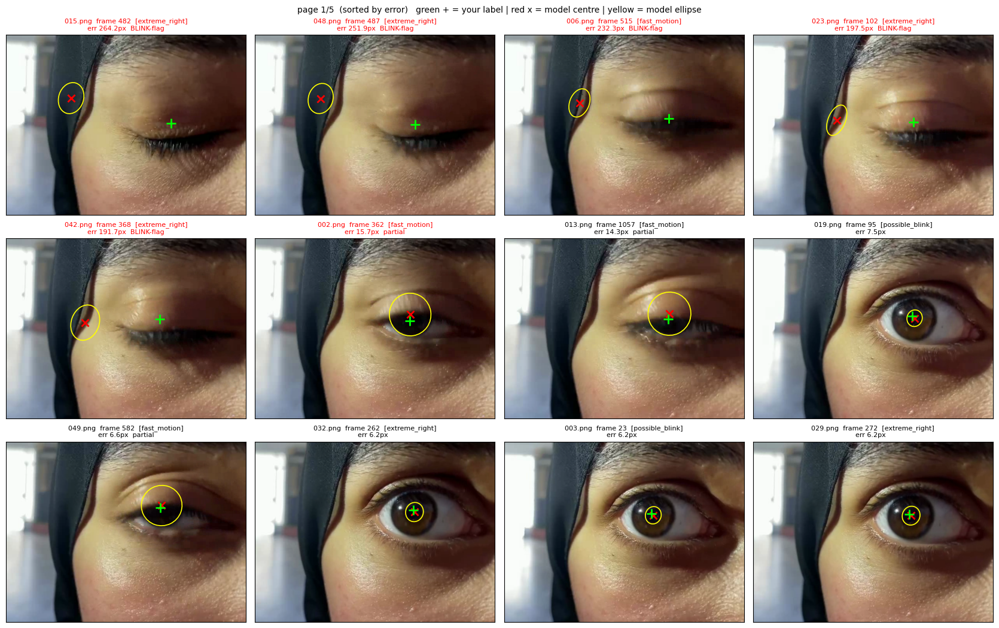

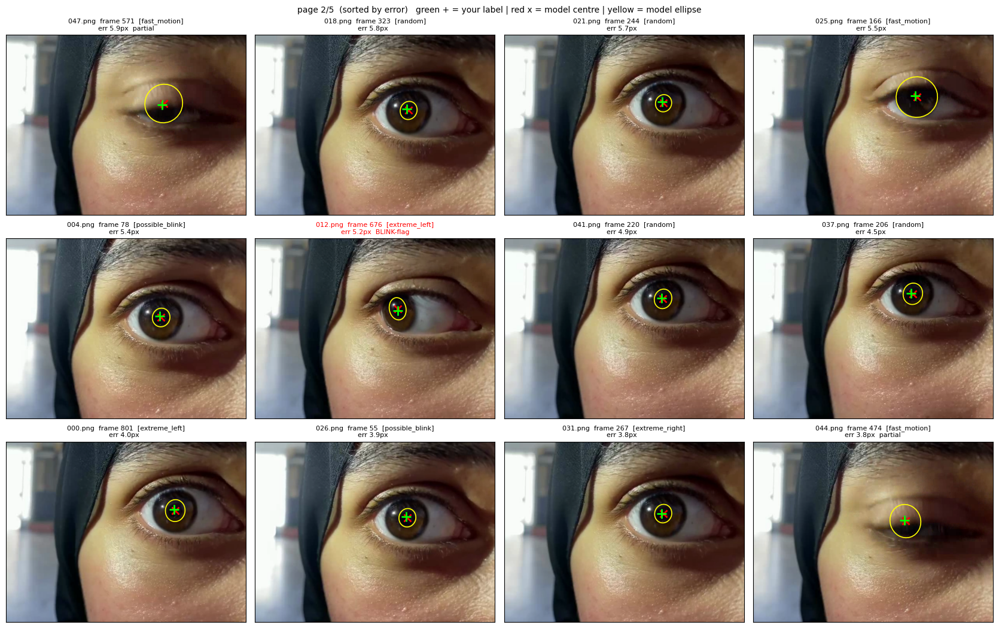

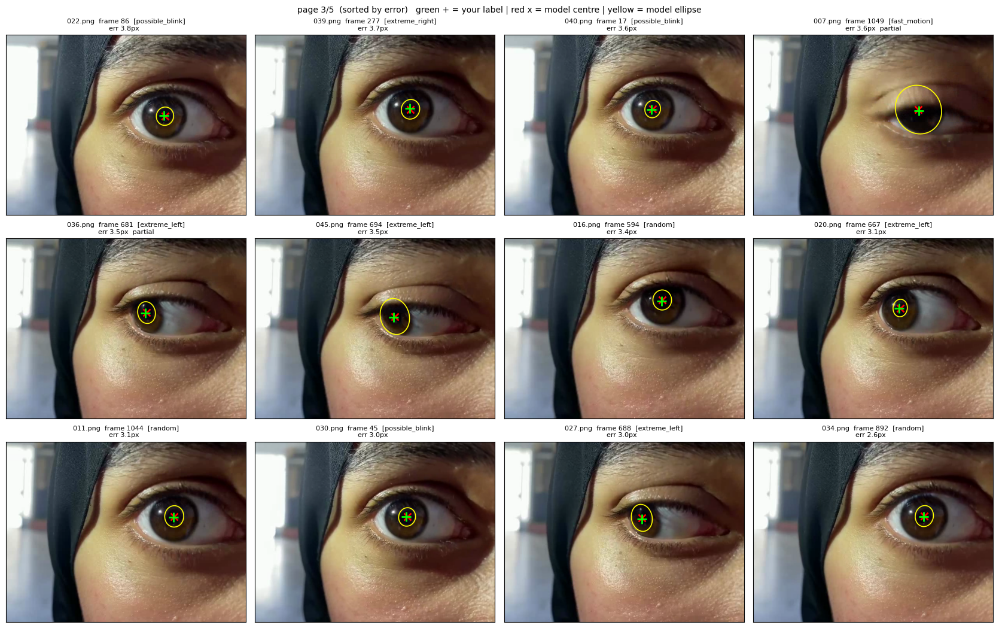

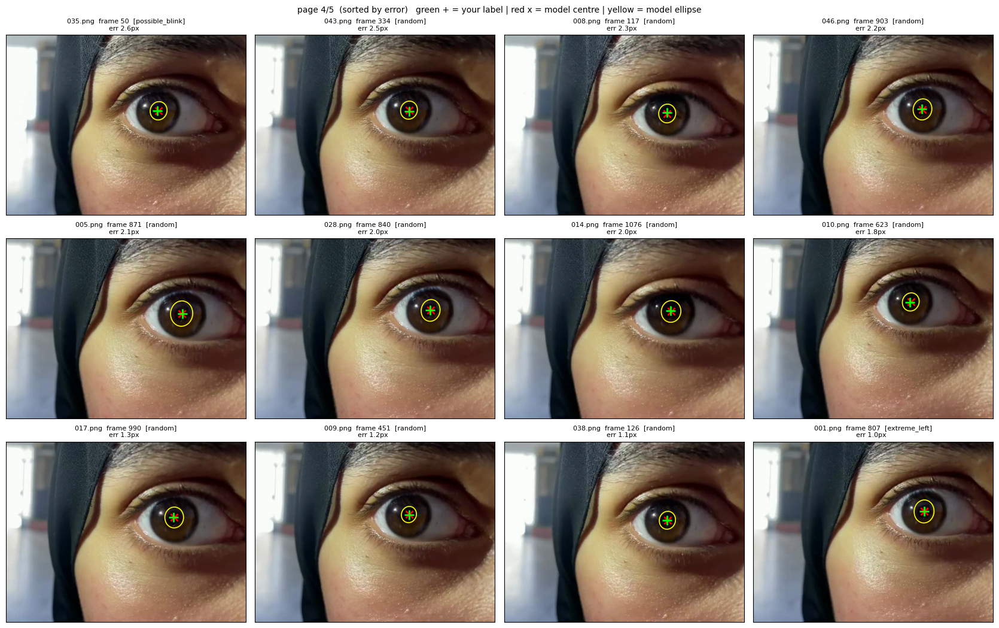

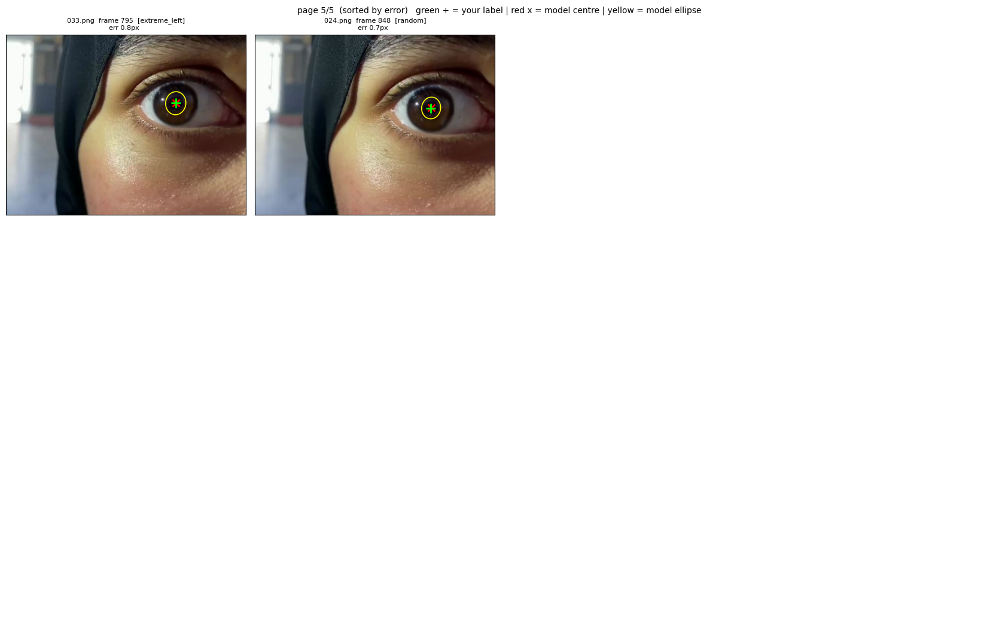

50 frames on 5 page(s); images also saved to /kaggle/working/gt_eval.  Single frame, large: show_frame('042.png')


In [10]:
# ===== VIEW ALL FRAMES (paste as a new cell AFTER Cell 4 of ellseg_gt_evaluation.ipynb) =====
# Green +  = your label        Red x = model pupil centre        Yellow ellipse = model pupil ellipse
# Red title = failure (error > FAIL_PX) or model flagged blink / no pupil
import numpy as np, matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

SORT_BY   = "error"    # "error" = worst first | "file" = 000,001,... | "x" = pupil position left -> right | "category"
PER_PAGE  = 12         # frames per page
COLS      = 4
FAIL_PX   = 15         # error above this = failure (red title)
ZOOM_HALF = None       # None = whole frame; e.g. 120 = show only a 240x240 px window around your label (pupil in detail)

sx_, sy_ = CW / NET_W, CH / NET_H
v = lab.copy()
v["err_px"] = np.hypot(v.pred_x - v.x, v.pred_y - v.y)          # NaN if no label or no model centre

if SORT_BY == "error":      order = v.sort_values("err_px", ascending=False, na_position="first").index
elif SORT_BY == "x":        order = v.sort_values("x", na_position="first").index
elif SORT_BY == "category": order = v.sort_values(["category", "file"]).index
else:                       order = v.sort_values("file").index
order = list(order)

def draw(ax, i, big=False):
    r = v.loc[i]
    im = imgs[i]
    x0 = y0 = 0
    if ZOOM_HALF and np.isfinite(r.x):
        x0 = int(np.clip(r.x - ZOOM_HALF, 0, max(CW - 2 * ZOOM_HALF, 0)))
        y0 = int(np.clip(r.y - ZOOM_HALF, 0, max(CH - 2 * ZOOM_HALF, 0)))
        im = im[y0:y0 + 2 * ZOOM_HALF, x0:x0 + 2 * ZOOM_HALF]
    ax.imshow(im, extent=(x0 - .5, x0 + im.shape[1] - .5, y0 + im.shape[0] - .5, y0 - .5))
    p = pe[i]
    if np.isfinite(p[0]):
        ax.add_patch(Ellipse((p[0] * sx_, p[1] * sy_), 2 * p[2] * sx_, 2 * p[3] * sy_,
                             angle=float(np.degrees(p[4])), fill=False, ec="yellow", lw=1.2))
        ax.plot(r.pred_x, r.pred_y, "x", color="red", ms=12 if big else 9, mew=2)
    if np.isfinite(r.x):
        ax.plot(r.x, r.y, "+", color="lime", ms=16 if big else 12, mew=2)
    ax.set_xlim(x0 - .5, x0 + im.shape[1] - .5); ax.set_ylim(y0 + im.shape[0] - .5, y0 - .5)
    ax.set_xticks([]); ax.set_yticks([])
    flags = []
    if not np.isfinite(r.pred_x): flags.append("NO ELLIPSE")
    if bool(r.model_blink):       flags.append("BLINK-flag")
    elif bool(r.partial):         flags.append("partial")
    if not np.isfinite(r.x):      flags.append("you: no pupil")
    err = f"err {r.err_px:.1f}px" if np.isfinite(r.err_px) else "err n/a"
    bad = (np.isfinite(r.err_px) and r.err_px > FAIL_PX) or bool(r.model_blink) or not np.isfinite(r.pred_x)
    ax.set_title(f"{r.file}  frame {int(r.frame)}  [{r.category}]\n{err}  {' '.join(flags)}",
                 fontsize=8, color="red" if bad else "black")

n_pages = int(np.ceil(len(order) / PER_PAGE))
rows = int(np.ceil(PER_PAGE / COLS))
for pg in range(n_pages):
    chunk = order[pg * PER_PAGE:(pg + 1) * PER_PAGE]
    fig, axes = plt.subplots(rows, COLS, figsize=(4.2 * COLS, 3.6 * rows)); axes = np.atleast_1d(axes).ravel()
    for a in axes: a.axis("off")
    for a, i in zip(axes, chunk):
        a.axis("on"); draw(a, i)
    fig.suptitle(f"page {pg + 1}/{n_pages}  (sorted by {SORT_BY})   green + = your label | red x = model centre | yellow = model ellipse", fontsize=10)
    plt.tight_layout()
    fig.savefig(OUT_DIR / f"all_frames_page{pg + 1}.png", dpi=80)
    plt.show()

def show_frame(name, zoom_half=None):
    """One frame, large:  show_frame('042.png')  or  show_frame('042.png', zoom_half=100)"""
    global ZOOM_HALF
    old, ZOOM_HALF = ZOOM_HALF, zoom_half
    i = int(v.index[v.file == name][0])
    fig, ax = plt.subplots(figsize=(10, 7.5)); draw(ax, i, big=True); plt.tight_layout(); plt.show()
    ZOOM_HALF = old
    print(v.loc[i, ["file", "frame", "category", "x", "y", "pred_x", "pred_y", "err_px", "contrast", "ellipse_ratio", "model_blink", "partial"]].to_string())

print(f"{len(order)} frames on {n_pages} page(s); images also saved to {OUT_DIR}.  Single frame, large: show_frame('042.png')")